In [1]:
import pandas as pd  # Work with the grid-stability dataset
from pathlib import Path  # Build reliable file paths

DATA_PATH = Path("../datasets/Data_for_UCI_named.csv")

df = pd.read_csv(DATA_PATH)  # Load the UCI grid-stability dataset

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (10000, 14)

Columns:
['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4', 'stab', 'stabf']


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [2]:
print(df["stabf"].value_counts())  # Count stable and unstable samples

print("\nClass percentages:")
print(
    df["stabf"].value_counts(normalize=True) * 100
)  # Check whether the classes are imbalanced

stabf
unstable    6380
stable      3620
Name: count, dtype: int64

Class percentages:
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [3]:
from sklearn.model_selection import train_test_split  # Create unbiased data splits
from sklearn.preprocessing import StandardScaler  # Put features on comparable scales

X = df.drop(columns=["stab", "stabf"])  # Remove target and leakage column
y = df["stabf"].map({"stable": 0, "unstable": 1})  # Treat instability as positive class

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,  # Preserve stable/unstable ratio in both sets
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)
print("Train classes:\n", y_train.value_counts())

Training: (8000, 12)
Testing : (2000, 12)
Train classes:
 stabf
1    5104
0    2896
Name: count, dtype: int64


In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train,  # Keep class distribution consistent
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

Train: (6400, 12)
Val  : (1600, 12)
Test : (2000, 12)


In [5]:
scaler = StandardScaler()  # Learn scaling only from training data

X_train_scaled = scaler.fit_transform(X_train)  # Learn mean/std here
X_val_scaled = scaler.transform(X_val)  # Reuse training statistics
X_test_scaled = scaler.transform(X_test)  # Never fit on test data

print("Scaled training shape:", X_train_scaled.shape)

Scaled training shape: (6400, 12)


In [6]:
import tensorflow as tf  # Build the ANN classifier

tf.random.set_seed(42)  # Make training more reproducible

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(12,)),
    tf.keras.layers.Dense(32, activation="relu"),  # Learn nonlinear feature combinations
    tf.keras.layers.Dense(16, activation="relu"),  # Compress learned representation
    tf.keras.layers.Dense(1, activation="sigmoid"),  # Output instability probability
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961 (3.75 KB)

 Trainable params: 961 (3.75 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,  # Return to best model instead of final epoch
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7666 - loss: 0.4878 - val_accuracy: 0.8119 - val_loss: 0.3936
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8316 - loss: 0.3696 - val_accuracy: 0.8325 - val_loss: 0.3531
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8539 - loss: 0.3224 - val_accuracy: 0.8562 - val_loss: 0.3134
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8770 - loss: 0.2776 - val_accuracy: 0.8737 - val_loss: 0.2758
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8994 - loss: 0.2400 - val_accuracy: 0.8950 - val_loss: 0.2453
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9155 - loss: 0.2112 - val_accuracy: 0.9062 - val_loss: 0.2220
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9212 - loss: 0.1905 - val_accuracy: 0.9156 - val_loss: 0.2072
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9253 - loss: 0.1758 - val_accu

In [8]:
from sklearn.metrics import classification_report, confusion_matrix

y_prob = model.predict(X_test_scaled).ravel()  # Predict instability probability
y_pred = (y_prob >= 0.5).astype(int)  # Convert probability into class

print(classification_report(
    y_test,
    y_pred,
    target_names=["stable", "unstable"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

      stable       0.96      0.94      0.95       724
    unstable       0.97      0.98      0.97      1276

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000

Confusion Matrix:
[[ 680   44]
 [  30 1246]]


In [13]:
from sklearn.metrics import roc_auc_score  # Compare probability-ranking quality

ann_prob = model.predict(
    X_test_scaled,
    verbose=0
).ravel()  # ANN probability that each state is unstable

ann_auc = roc_auc_score(
    y_test,
    ann_prob
)  # Calculate ANN ROC-AUC

print("ANN ROC-AUC:", ann_auc)

ANN ROC-AUC: 0.9938462304508219


In [9]:
from xgboost import XGBClassifier  # Gradient-boosted trees for stability classification

xgb_model = XGBClassifier(
    n_estimators=400,  # Build enough trees to learn nonlinear stability boundaries
    max_depth=6,  # Limit individual tree complexity to reduce overfitting
    learning_rate=0.05,  # Learn gradually instead of making aggressive updates
    subsample=0.8,  # Train each tree on part of the samples for better generalization
    colsample_bytree=0.8,  # Use a subset of features for each tree
    objective="binary:logistic",  # Predict stable/unstable probability
    eval_metric="logloss",  # Measure binary classification error during training
    random_state=42,
)

xgb_model.fit(X_train, y_train)  # Train using the same samples as the ANN

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [10]:
from sklearn.metrics import classification_report, confusion_matrix  # Evaluate predictions
from sklearn.metrics import accuracy_score, roc_auc_score  # Calculate summary metrics

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]  # Probability of unstable class
xgb_pred = (xgb_prob >= 0.5).astype(int)  # Convert probability into 0/1 class

print(classification_report(
    y_test,
    xgb_pred,
    target_names=["stable", "unstable"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("ROC-AUC :", roc_auc_score(y_test, xgb_prob))

              precision    recall  f1-score   support

      stable       0.95      0.91      0.93       724
    unstable       0.95      0.97      0.96      1276

    accuracy                           0.95      2000
   macro avg       0.95      0.94      0.94      2000
weighted avg       0.95      0.95      0.95      2000

Confusion Matrix:
[[ 657   67]
 [  35 1241]]
Accuracy: 0.949
ROC-AUC : 0.9921478550026845


In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score  # Comparison metrics

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1": f1_score(y_test, xgb_pred),
    "ROC_AUC": roc_auc_score(y_test, xgb_prob),
}

print(xgb_results)

{'Model': 'XGBoost', 'Accuracy': 0.949, 'Precision': 0.9487767584097859, 'Recall': 0.9725705329153606, 'F1': 0.9605263157894737, 'ROC_AUC': 0.9921478550026845}


In [12]:
from pathlib import Path  # Create model directory safely

MODEL_DIR = Path("../saved_models")
MODEL_DIR.mkdir(exist_ok=True)  # Ensure the output directory exists

xgb_model.save_model(
    MODEL_DIR / "grid_stability_xgboost.json"
)  # Save trained model for digital-twin inference

In [14]:
ann_val_prob = model.predict(
    X_val_scaled,
    verbose=0
).ravel()  # ANN probability of instability on validation samples

xgb_val_prob = xgb_model.predict_proba(
    X_val
)[:, 1]  # XGBoost probability for the exact same validation samples

print("ANN validation predictions:", ann_val_prob.shape)
print("XGB validation predictions:", xgb_val_prob.shape)

ANN validation predictions: (1600,)
XGB validation predictions: (1600,)


In [15]:
import numpy as np  # Search candidate ensemble weights
from sklearn.metrics import f1_score  # Evaluate unstable-class performance

best_alpha = 0
best_f1 = -1

for alpha in np.arange(0, 1.01, 0.05):
    prob = alpha * ann_val_prob + (1 - alpha) * xgb_val_prob
    pred = (prob >= 0.5).astype(int)
    score = f1_score(y_val, pred)

    if score > best_f1:
        best_alpha = alpha
        best_f1 = score

print("ANN weight     :", best_alpha)
print("XGBoost weight :", 1 - best_alpha)
print("Validation F1  :", best_f1)

ANN weight     : 0.25
XGBoost weight : 0.75
Validation F1  : 0.967710843373494


In [16]:
hybrid_prob = (
    best_alpha * ann_prob
    + (1 - best_alpha) * xgb_prob
)  # Combine ANN and XGBoost test probabilities

hybrid_pred = (
    hybrid_prob >= 0.5
).astype(int)  # Convert probability into stable/unstable prediction

In [17]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, roc_auc_score

print(classification_report(
    y_test,
    hybrid_pred,
    target_names=["stable", "unstable"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, hybrid_pred))

print("Accuracy:", accuracy_score(y_test, hybrid_pred))
print("ROC-AUC :", roc_auc_score(y_test, hybrid_prob))

              precision    recall  f1-score   support

      stable       0.96      0.92      0.94       724
    unstable       0.96      0.98      0.97      1276

    accuracy                           0.96      2000
   macro avg       0.96      0.95      0.96      2000
weighted avg       0.96      0.96      0.96      2000

Confusion Matrix:
[[ 669   55]
 [  25 1251]]
Accuracy: 0.96
ROC-AUC : 0.9948778122239734


In [19]:
hybrid_val_prob = (
    best_alpha * ann_val_prob
    + (1 - best_alpha) * xgb_val_prob
)  # Combine validation probabilities using selected weights

In [20]:
from sklearn.metrics import fbeta_score  # F2 gives extra importance to recall
import numpy as np  # Test several decision thresholds

best_threshold = 0.5
best_f2 = -1

for threshold in np.arange(0.30, 0.71, 0.01):
    pred = (hybrid_val_prob >= threshold).astype(int)
    score = fbeta_score(y_val, pred, beta=2)  # Penalize missed instability more heavily

    if score > best_f2:
        best_f2 = score
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Validation F2 :", best_f2)

Best threshold: 0.5000000000000002
Validation F2 : 0.977033865317244


In [21]:
hybrid_tuned_pred = (
    hybrid_prob >= best_threshold
).astype(int)  # Apply only the validation-selected threshold to test data

print(classification_report(
    y_test,
    hybrid_tuned_pred,
    target_names=["stable", "unstable"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, hybrid_tuned_pred))

              precision    recall  f1-score   support

      stable       0.96      0.92      0.94       724
    unstable       0.96      0.98      0.97      1276

    accuracy                           0.96      2000
   macro avg       0.96      0.95      0.96      2000
weighted avg       0.96      0.96      0.96      2000

Confusion Matrix:
[[ 669   55]
 [  25 1251]]


In [22]:
comparison = pd.DataFrame([
    {
        "Model": "Deep ANN",
        "Accuracy": 0.963,
        "ROC-AUC": 0.993846,
        "Missed Unstable": 30,
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.949,
        "ROC-AUC": 0.992148,
        "Missed Unstable": 35,
    },
    {
        "Model": "ANN + XGBoost Hybrid",
        "Accuracy": 0.960,
        "ROC-AUC": 0.994878,
        "Missed Unstable": 25,
    },
])

display(comparison)

,Model,Accuracy,ROC-AUC,Missed Unstable
0,Deep ANN,0.963,0.993846,30
1,XGBoost,0.949,0.992148,35
2,ANN + XGBoost Hybrid,0.960,0.994878,25


In [23]:
MODEL_DIR.mkdir(exist_ok=True)  # Ensure the model directory exists

model.save(
    MODEL_DIR / "grid_stability_ann.keras"
)  # Save the trained neural network

In [24]:
import joblib  # Save preprocessing objects for later inference

joblib.dump(
    scaler,
    MODEL_DIR / "grid_stability_scaler.pkl"
)  # Preserve the training-data scaling parameters

['..\\saved_models\\grid_stability_scaler.pkl']

In [25]:
hybrid_config = {
    "ann_weight": float(best_alpha),
    "xgb_weight": float(1 - best_alpha),
    "threshold": float(best_threshold),
}

joblib.dump(
    hybrid_config,
    MODEL_DIR / "grid_stability_hybrid_config.pkl"
)

['..\\saved_models\\grid_stability_hybrid_config.pkl']

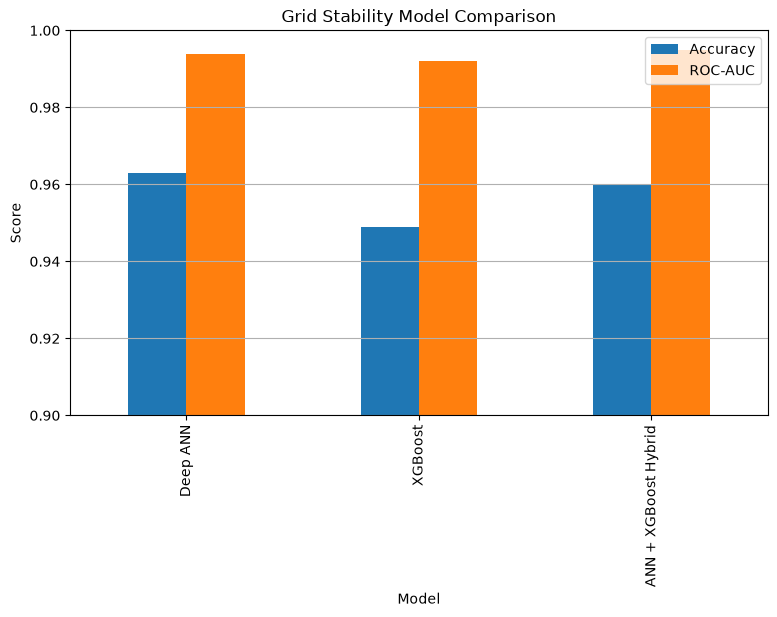

In [27]:
import matplotlib.pyplot as plt  # Visualize model comparison
comparison.plot(
    x="Model",
    y=["Accuracy", "ROC-AUC"],
    kind="bar",
    figsize=(9, 5),
)

plt.ylabel("Score")
plt.title("Grid Stability Model Comparison")
plt.ylim(0.90, 1.00)
plt.grid(axis="y")
plt.show()